# Criiq — Full Model Evaluation Suite

One notebook, three questions, each with real numbers computed live (nothing
hand-typed):

- **Part A — WPA regressors**: MAE, RMSE, R², Pearson/Spearman correlation,
  top-quartile hit-rate, and sign-agreement accuracy for `batting_wpa`/
  `bowling_wpa`, both genders, on a proper temporal (never-seen-future)
  holdout.
- **Part B — XI selection (the MILP)**: does `select_xi` actually respect its
  own constraints, how much score does enforcing those constraints cost vs.
  an unconstrained top-11, and how well does the resulting XI overlap with
  real historical starting XIs on genuinely unseen matches.
- **Part C — GA fitness (bowling rotation & batting order)**: convergence
  behaviour across generations, run-to-run stability across random seeds, and
  improvement over a naive non-AI baseline (reusing `simulate/lineup_explain.py`,
  the project's own baseline-comparison explainability layer).

Runtime note: Part C runs several real genetic-algorithm searches — expect
this notebook to take on the order of 15-25 minutes end to end, most of it in
Part C. Every random-search step below fixes `rng_seed` for exact
reproducibility of *this notebook's own numbers* (the production CLI omits a
seed by default so every real run explores fresh randomness — see
`ALGORITHMS.md` §2 for why).

See `VALIDATION_REPORT.md` for the full-scale, dated version of Part B's
real-world overlap test (142 team-selections, not this notebook's smaller
sample) and the project's overall validation history.

## Setup

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from criiq_models.db import connect
from criiq_models.config import SETTINGS
from criiq_models.features.historical import build_training_table
from criiq_models.features.schema import MODEL_FEATURES, TARGETS
from criiq_models.recommend.train import _make_model, _clip_target, load_metadata
from criiq_models.evaluate.backtest import backtest, _top_quartile_hit_rate
from criiq_models.roster import team_pool
from criiq_models.recommend.score import RecommendationScorer
from criiq_models.selection.optimize import select_xi
from criiq_models.features.common import bowling_capable, batting_capable
from criiq_models.features.current import resolve_role
from criiq_models.simulate.outcomes import build_outcome_model, build_player_profiles
from criiq_models.simulate.ga_bowling import optimize_bowling_rotation
from criiq_models.simulate.ga_batting import optimize_batting_order
from criiq_models.simulate.lineup_explain import explain_bowling_rotation, explain_batting_order
from criiq_models.cli import _batting_groups, _primary_bowlers, _bowling_pool

conn = connect()
FMT = "T20"
random.seed(42)
np.random.seed(42)
plt.rcParams["figure.dpi"] = 100

print("Shipped model metadata (what's actually being evaluated):")
for g in ("female", "male"):
    md_ = load_metadata(FMT, g)
    print(f"  {g}: trained_at={md_.get('trained_at')}, n_rows_total={md_.get('n_rows_total')}")

Shipped model metadata (what's actually being evaluated):
  female: trained_at=2026-07-31T22:10:04, n_rows_total=40969
  male: trained_at=2026-07-31T22:12:25, n_rows_total=71876


## Part A — WPA regressor accuracy (`batting_wpa` / `bowling_wpa`)

Same temporal holdout `evaluate/backtest.py` uses in production (80th-percentile
match-date cutoff, never a row-level split, since rows from the same match are
correlated) — a **freshly-fit** model on the training side of that exact split,
scored against the raw, unclipped test-side labels. This is the decision-driving
evaluation the project actually uses to pick model families/hyperparameters
(see `ALGORITHMS.md` §3.5), extended here with the full regression-metrics
suite (RMSE, R², Spearman, sign-agreement) beyond what `backtest()` itself
returns.

In [2]:
def temporal_split(conn, fmt, gender):
    table = build_training_table(conn, fmt, gender)
    dates = pd.to_datetime(table["date"])
    cutoff = dates.quantile(1 - SETTINGS.backtest_test_fraction)
    return table[dates < cutoff].copy(), table[dates >= cutoff].copy(), cutoff

def full_metrics(conn, fmt, gender, target):
    train_df, test_df, cutoff = temporal_split(conn, fmt, gender)
    train_rows = train_df.dropna(subset=[target])
    test_rows = test_df.dropna(subset=[target]).copy()

    model = _make_model(target, gender)
    model.fit(train_rows[MODEL_FEATURES], _clip_target(train_rows[target]))
    pred = model.predict(test_rows[MODEL_FEATURES])
    actual = test_rows[target].to_numpy()
    test_rows["_pred"] = pred

    baseline_pred = np.full_like(actual, train_rows[target].mean())
    pearson_r, _ = stats.pearsonr(pred, actual)
    spearman_r, _ = stats.spearmanr(pred, actual)

    # sign-agreement: among players with a genuinely nonzero actual WPA, did
    # the model at least get the direction (helped vs hurt the team) right?
    nonzero = actual != 0
    sign_agreement = float(np.mean(np.sign(pred[nonzero]) == np.sign(actual[nonzero]))) if nonzero.any() else None

    return {
        "gender": gender, "target": target, "cutoff_date": str(cutoff.date()),
        "n_train": len(train_rows), "n_test": len(test_rows),
        "MAE": mean_absolute_error(actual, pred),
        "baseline_MAE_mean_predictor": mean_absolute_error(actual, baseline_pred),
        "RMSE": mean_squared_error(actual, pred) ** 0.5,
        "baseline_RMSE": mean_squared_error(actual, baseline_pred) ** 0.5,
        "R2": r2_score(actual, pred),
        "baseline_R2": r2_score(actual, baseline_pred),
        "pearson_r": pearson_r, "spearman_r": spearman_r,
        "top_quartile_hit_rate": _top_quartile_hit_rate(test_rows, target),
        "sign_agreement_accuracy": sign_agreement,
    }, pred, actual

results_a = {}
rows = []
for gender in ("female", "male"):
    for target in TARGETS:
        metrics, pred, actual = full_metrics(conn, FMT, gender, target)
        results_a[(gender, target)] = (pred, actual)
        rows.append(metrics)

metrics_df = pd.DataFrame(rows).set_index(["gender", "target"])
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
metrics_df[["n_train", "n_test", "MAE", "baseline_MAE_mean_predictor", "RMSE",
            "baseline_RMSE", "R2", "baseline_R2", "pearson_r", "spearman_r",
            "top_quartile_hit_rate", "sign_agreement_accuracy"]]

n_train  n_test    MAE  baseline_MAE_mean_predictor  \
gender target                                                             
female batting_wpa    32536    8159 0.0947                       0.0961   
       bowling_wpa    32536    8159 0.0772                       0.0785   
male   batting_wpa    56290   14024 0.0887                       0.0896   
       bowling_wpa    56290   14024 0.0697                       0.0709   

                     RMSE  baseline_RMSE     R2  baseline_R2  pearson_r  \
gender target                                                             
female batting_wpa 0.1508         0.1518 0.0136      -0.0000     0.1254   
       bowling_wpa 0.1296         0.1300 0.0063      -0.0000     0.0798   
male   batting_wpa 0.1429         0.1434 0.0074      -0.0000     0.0914   
       bowling_wpa 0.1209         0.1213 0.0054      -0.0000     0.0752   

                    spearman_r  top_quartile_hit_rate  sign_agreement_accuracy  
gender target                                                                   
female batting_wpa      0.0894                 0.3540                   0.5259  
       bowling_wpa      0.0854                 0.2750                   0.5552  
male   batting_wpa      0.0733                 0.3080                   0.5181  
       bowling_wpa      0.0706                 0.2530                   0.5441

**Reading `R2` honestly:** a near-zero (or even a hair negative) R² here is
*expected*, not a bug — it's the same finding `ALGORITHMS.md`/`VALIDATION_REPORT.md`
report elsewhere: single-match WPA is an extremely high-variance target (one
big innings dominates it), so R² (which measures *how much of the raw
variance* the model explains) stays low even when the model is genuinely
extracting real signal — which is exactly why `pearson_r`/`spearman_r`
(correlation/rank-agreement) and `top_quartile_hit_rate` are the more
informative columns for a *ranking* task like this, not `R2` in isolation.

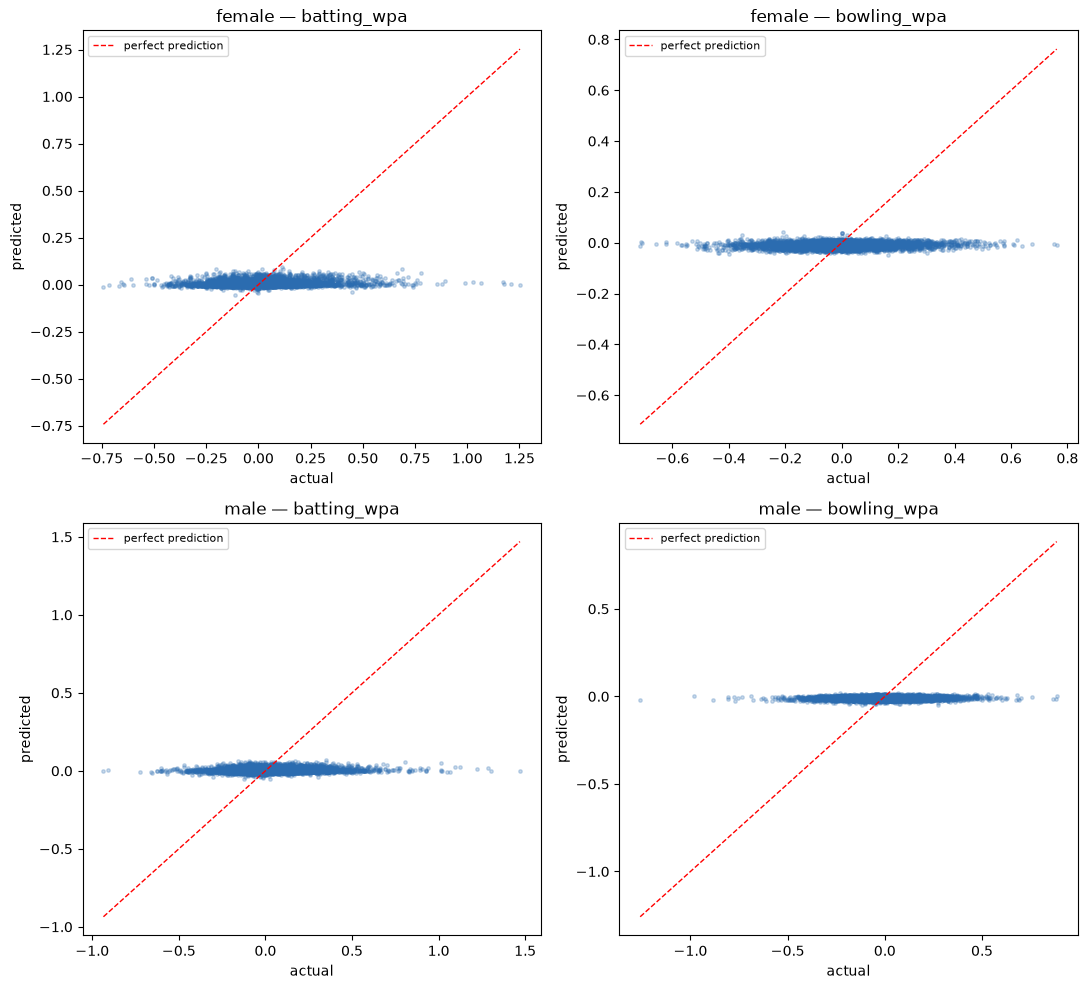

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, ((gender, target), (pred, actual)) in zip(axes.flat, results_a.items()):
    ax.scatter(actual, pred, s=6, alpha=0.25, color="#2b6cb0")
    lo, hi = min(actual.min(), pred.min()), max(actual.max(), pred.max())
    ax.plot([lo, hi], [lo, hi], color="red", linewidth=1, linestyle="--", label="perfect prediction")
    ax.set_xlabel("actual"); ax.set_ylabel("predicted")
    ax.set_title(f"{gender} — {target}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

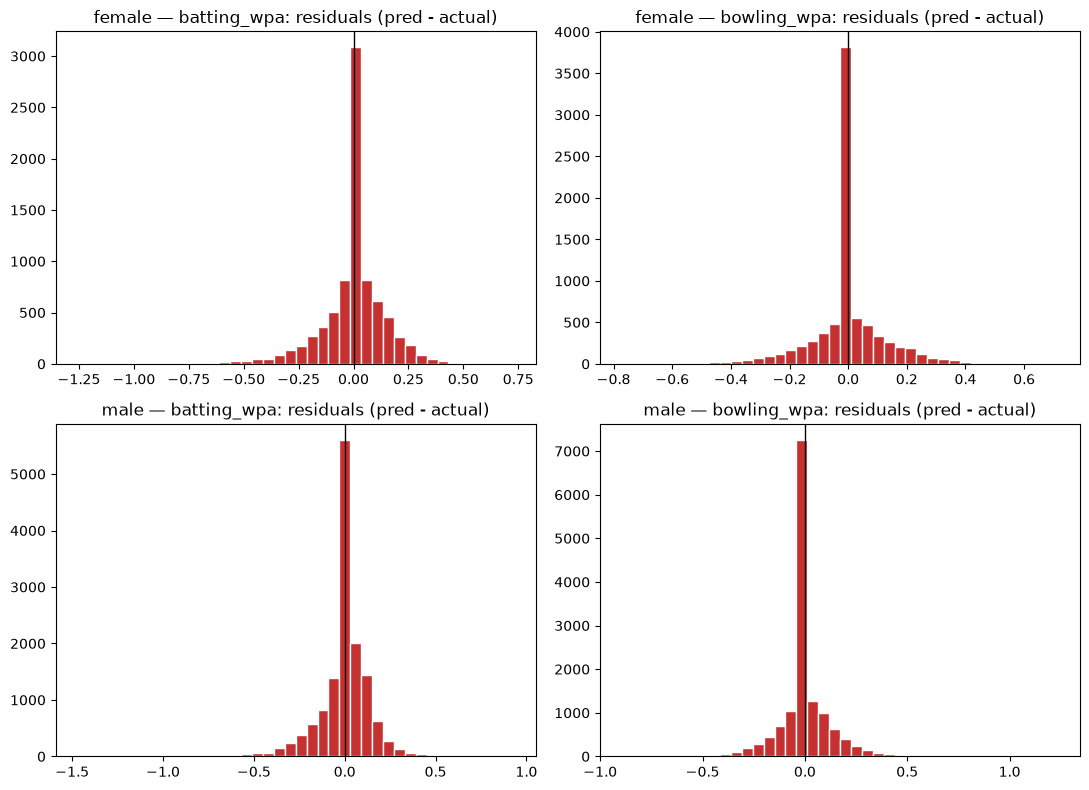

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, ((gender, target), (pred, actual)) in zip(axes.flat, results_a.items()):
    residuals = pred - actual
    ax.hist(residuals, bins=40, color="#c53030", edgecolor="white")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{gender} — {target}: residuals (pred - actual)")
plt.tight_layout()
plt.show()

## Part B — XI selection (MILP) quality

`select_xi` isn't a regression model, so "accuracy" here means three different
things, each tested directly:

1. **Constraint compliance** — does the MILP actually always respect the
   constraints it's supposed to (exactly 11 selected; batting/bowling-capable
   minimums; keeper/opener minimums, soft-degraded where the pool can't
   support them)?
2. **Cost of the constraints** — how much total score is given up by
   requiring a legal, balanced XI instead of just taking the unconstrained
   top-11 by score (which can be an all-batter side with no keeper)?
3. **Real-world overlap** — on genuinely unseen real matches, how much does
   the recommended XI actually overlap with the real historical starting XI,
   vs. a random-11-from-the-same-pool baseline?

In [2]:
teams_sample = pd.read_sql_query(
    "SELECT DISTINCT team1 AS team FROM matches "
    "WHERE format=? AND gender='female' AND team_type='international' "
    "GROUP BY team1 HAVING COUNT(*) >= 20 ORDER BY RANDOM() LIMIT 8",
    conn, params=(FMT,))["team"].tolist()
print("Sample of real T20I countries used for Part B (team_type='international' only --")
print("excludes domestic league franchises like WBBL/The Hundred sides):", teams_sample)

scorer = RecommendationScorer(conn, FMT, "female")

compliance_rows = []
N_RANDOM_DRAWS = 200
for team in teams_sample:
    for opponent in teams_sample:
        if team == opponent:
            continue
        pool = team_pool(conn, team, FMT, "female")
        if len(pool) < 11:
            continue
        scored = scorer.score_many(pool, opponent)
        xi = select_xi(scored)
        xi_ids = {p["player_id"] for p in xi["xi"]}

        by_id = {p["player_id"]: p for p in scored}
        bat_capable = sum(1 for pid in xi_ids if batting_capable(by_id[pid]["role_bucket"]))
        bowl_capable = sum(1 for pid in xi_ids if bowling_capable(by_id[pid]["role_bucket"]))
        keepers = sum(1 for pid in xi_ids if by_id[pid].get("is_keeper"))
        pool_keepers = sum(1 for p in scored if p.get("is_keeper"))

        milp_score = sum(by_id[pid]["score"] for pid in xi_ids)
        naive_top11 = sorted(scored, key=lambda p: -p["score"])[:11]
        naive_score = sum(p["score"] for p in naive_top11)
        naive_bat = sum(1 for p in naive_top11 if batting_capable(p["role_bucket"]))
        naive_bowl = sum(1 for p in naive_top11 if bowling_capable(p["role_bucket"]))
        naive_keepers = sum(1 for p in naive_top11 if p.get("is_keeper"))
        naive_violates = (naive_bat < min(5, len(scored)) or naive_bowl < min(5, len(scored))
                           or (pool_keepers > 0 and naive_keepers == 0))

        random_scores = [sum(by_id[pid]["score"] for pid in random.sample(pool, 11)) for _ in range(N_RANDOM_DRAWS)]

        compliance_rows.append({
            "team": team, "opponent": opponent, "pool_size": len(pool),
            "xi_size_ok": len(xi_ids) == min(11, len(pool)),
            "min_batting_ok": bat_capable >= min(SETTINGS.min_batting_capable, sum(1 for p in scored if batting_capable(p["role_bucket"]))),
            "min_bowling_ok": bowl_capable >= min(SETTINGS.min_bowling_capable, sum(1 for p in scored if bowling_capable(p["role_bucket"]))),
            "keeper_ok": keepers >= min(SETTINGS.min_keepers, pool_keepers),
            "milp_score": milp_score, "naive_top11_score": naive_score,
            "naive_top11_violates_constraints": naive_violates,
            "random_mean_score": np.mean(random_scores),
        })

comp_df = pd.DataFrame(compliance_rows)
print(f"\n{len(comp_df)} (team, opponent) pools checked, real T20I countries only.\n")
print("Constraint compliance (should be 100% across the board):")
print(comp_df[["xi_size_ok", "min_batting_ok", "min_bowling_ok", "keeper_ok"]].mean().apply(lambda x: f"{100*x:.1f}%"))

comp_df["score_gap_vs_naive"] = comp_df["milp_score"] - comp_df["naive_top11_score"]
comp_df["score_gap_vs_random"] = comp_df["milp_score"] - comp_df["random_mean_score"]
print(f"\nMean constrained-XI score:      {comp_df['milp_score'].mean():.1f}")
print(f"Mean unconstrained top-11 score: {comp_df['naive_top11_score'].mean():.1f}  "
      f"(gap: {comp_df['score_gap_vs_naive'].mean():+.1f} -- the real cost of requiring a legal, balanced side)")
print(f"Mean random-11 score:            {comp_df['random_mean_score'].mean():.1f}  "
      f"(gap: {comp_df['score_gap_vs_random'].mean():+.1f} -- the value the optimizer actually adds over guessing)")
print(f"Unconstrained top-11 would have violated a real constraint in "
      f"{100*comp_df['naive_top11_violates_constraints'].mean():.1f}% of these pools -- "
      f"exactly the failure mode select_xi exists to prevent.")

Sample of real T20I countries used for Part B (team_type='international' only --
excludes domestic league franchises like WBBL/The Hundred sides): ['Rwanda', 'Mozambique', 'Kuwait', 'New Zealand', 'Kenya', 'Hong Kong', 'Zimbabwe', 'Bahrain']



56 (team, opponent) pools checked, real T20I countries only.

Constraint compliance (should be 100% across the board):
xi_size_ok        100.0%
min_batting_ok    100.0%
min_bowling_ok    100.0%
keeper_ok         100.0%
dtype: str

Mean constrained-XI score:      247.9
Mean unconstrained top-11 score: 249.4  (gap: -1.4 -- the real cost of requiring a legal, balanced side)
Mean random-11 score:            195.3  (gap: +52.6 -- the value the optimizer actually adds over guessing)
Unconstrained top-11 would have violated a real constraint in 26.8% of these pools -- exactly the failure mode select_xi exists to prevent.


### Real-world overlap — recommended XI vs. the actual historical starting XI

Same methodology as `VALIDATION_REPORT.md` §11a/§14 (full write-up and the
full-scale 142-comparison result live there) — a smaller sample here, sized
for notebook runtime, against the same genuinely-unseen forward-holdout
matches (`matches_holdout`/`match_players_holdout`, dated after this
package's `data_cutoff_date`, which the shipped models have never seen in any
form).

16 real team-selections checked (sample, for the full 142-comparison result see VALIDATION_REPORT.md).
Mean AI-predicted XI overlap with the real, actually-fielded XI: 6.75 / 11 (61.4%)
Mean random-11-from-pool baseline:                              4.86 / 11 (44.1%)

--- Worked example: New Zealand vs Sri Lanka (female, real match 1490683) ---
  predicted: SFM Devine  <- also in real XI
  predicted: SW Bates
  predicted: AC Kerr  <- also in real XI
  predicted: ML Green  <- also in real XI
  predicted: GE Plimmer  <- also in real XI
  predicted: IC Gaze  <- also in real XI
  predicted: BM Halliday  <- also in real XI
  predicted: NH Patel  <- also in real XI
  predicted: JM Kerr  <- also in real XI
  predicted: BG Illing  <- also in real XI
  predicted: LMM Tahuhu

  actual:    AC Kerr  <- AI predicted this player
  actual:    BG Illing  <- AI predicted this player
  actual:    BM Halliday  <- AI predicted this player
  actual:    GE Plimmer  <- AI predicted this player
  actual:    I

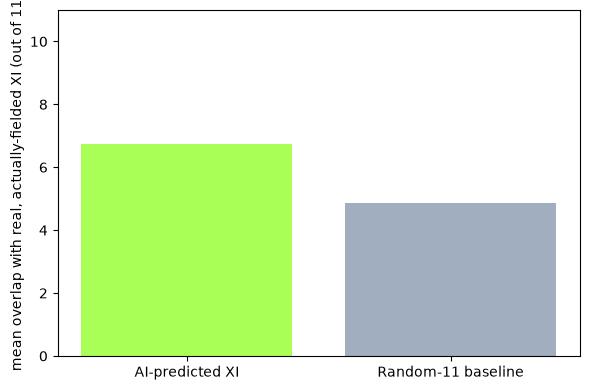

In [3]:
# The centerpiece of Part B: what the AI would have picked (predicted XI) vs.
# what the real coach actually fielded (actual XI), on matches the shipped
# models have never seen in any form (data-collection's forward holdout).
ident_by_name = {r["player_name"]: r["identifier"] for r in conn.execute("SELECT player_name, identifier FROM identifier_map")}
from criiq_models.roster import _player_id_map
unambiguous, split_map = _player_id_map(conn)

def resolve_name(name, gender):
    ident = ident_by_name.get(name)
    if ident is None:
        return None
    return unambiguous.get(ident) or split_map.get((ident, gender))

def actual_xi(match_id, team, gender):
    names = [r["player_name"] for r in conn.execute(
        "SELECT player_name FROM match_players_holdout WHERE match_id=? AND team=?", (match_id, team))]
    ids = [resolve_name(n, gender) for n in names]
    return [i for i in ids if i]

def name_of(pid):
    row = conn.execute("SELECT canonical_name FROM players WHERE player_id=?", (pid,)).fetchone()
    return row["canonical_name"] if row and row["canonical_name"] else pid

holdout_matches = pd.read_sql_query(
    "SELECT match_id, gender, team1, team2, venue_id FROM matches_holdout ORDER BY RANDOM() LIMIT 20", conn)

overlap_rows = []
worked_example = None
for _, m in holdout_matches.iterrows():
    for team, opponent in ((m.team1, m.team2), (m.team2, m.team1)):
        actual_ids = actual_xi(m.match_id, team, m.gender)
        if len(actual_ids) < 10:
            continue
        pool = team_pool(conn, team, FMT, m.gender)
        if len(pool) < 11:
            continue
        gender_scorer = scorer if m.gender == "female" else RecommendationScorer(conn, FMT, "male")
        scored = gender_scorer.score_many(pool, opponent, venue_id=m.venue_id)
        xi_ids = [p["player_id"] for p in select_xi(scored)["xi"]]
        common = set(xi_ids) & set(actual_ids)
        overlap = len(common)
        random_overlap = np.mean([len(set(random.sample(pool, 11)) & set(actual_ids)) for _ in range(200)])
        overlap_rows.append({"gender": m.gender, "team": team, "opponent": opponent, "overlap": overlap, "random_baseline": random_overlap})
        # Grab the first full (11/11 resolved) comparison as a concrete, named example.
        if worked_example is None and len(actual_ids) == 11:
            worked_example = {
                "match_id": m.match_id, "team": team, "opponent": opponent, "gender": m.gender,
                "predicted": [(pid, name_of(pid)) for pid in xi_ids],
                "actual": [(pid, name_of(pid)) for pid in actual_ids],
                "common": common,
            }

overlap_df = pd.DataFrame(overlap_rows)
print(f"{len(overlap_df)} real team-selections checked (sample, for the full 142-comparison result see VALIDATION_REPORT.md).")
print(f"Mean AI-predicted XI overlap with the real, actually-fielded XI: {overlap_df['overlap'].mean():.2f} / 11 "
      f"({100*overlap_df['overlap'].mean()/11:.1f}%)")
print(f"Mean random-11-from-pool baseline:                              {overlap_df['random_baseline'].mean():.2f} / 11 "
      f"({100*overlap_df['random_baseline'].mean()/11:.1f}%)")

if worked_example:
    we = worked_example
    print(f"\n--- Worked example: {we['team']} vs {we['opponent']} ({we['gender']}, real match {we['match_id']}) ---")
    for ppid, pname in we["predicted"]:
        mark = "  <- also in real XI" if ppid in we["common"] else ""
        print(f"  predicted: {pname}{mark}")
    print()
    for apid, aname in we["actual"]:
        mark = "  <- AI predicted this player" if apid in we["common"] else ""
        print(f"  actual:    {aname}{mark}")
    print(f"\nPlayers in common: {len(we['common'])} / 11 ({100*len(we['common'])/11:.0f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["AI-predicted XI", "Random-11 baseline"],
       [overlap_df["overlap"].mean(), overlap_df["random_baseline"].mean()],
       color=["#AAFF57", "#a0aec0"])
ax.set_ylabel("mean overlap with real, actually-fielded XI (out of 11)")
ax.set_ylim(0, 11)
plt.tight_layout()
plt.show()

### Named matchup spotlight: India vs Australia (Women), England vs India (Men)

Two specific, recognizable matchups, each on the **latest genuinely-unseen
real match** available between that pair (from `matches_holdout` -- the
shipped models have never trained on either match in any form). Same method
as the worked example above, run for both sides of each match so the
comparison isn't cherry-picked to whichever side happened to overlap well.

In [4]:
def worked_example(match_id, team, opponent, gender, venue_id=None):
    actual_ids = actual_xi(match_id, team, gender)
    pool = team_pool(conn, team, FMT, gender)
    print(f"\n{'='*70}\n{team} vs {opponent} ({gender}, match {match_id})")
    print(f"Real XI resolved: {len(actual_ids)}/11, candidate pool size: {len(pool)}")
    if len(actual_ids) < 10 or len(pool) < 11:
        print("Not enough data to compare (skipping).")
        return None
    gender_scorer = scorer if gender == "female" else RecommendationScorer(conn, FMT, "male")
    scored = gender_scorer.score_many(pool, opponent, venue_id=venue_id)
    xi_ids = [p["player_id"] for p in select_xi(scored)["xi"]]
    common = set(xi_ids) & set(actual_ids)
    print(f"\n{'AI-PREDICTED XI':<32}{'':<5}{'ACTUAL REAL XI':<32}")
    pred_names = [name_of(p) for p in xi_ids]
    act_names = [name_of(p) for p in actual_ids]
    for i in range(max(len(pred_names), len(act_names))):
        p = pred_names[i] if i < len(pred_names) else ""
        a = act_names[i] if i < len(act_names) else ""
        pmark = "*" if i < len(xi_ids) and xi_ids[i] in common else " "
        amark = "*" if i < len(actual_ids) and actual_ids[i] in common else " "
        print(f"{pmark} {p:<30}   {amark} {a:<30}")
    print(f"\n'*' = also appears in the other list. Overlap: {len(common)}/11 ({100*len(common)/11:.0f}%)")
    return len(common)

# India vs Australia, women -- latest genuinely-unseen match
worked_example("1490706", "India", "Australia", "female")
worked_example("1490706", "Australia", "India", "female")

# India vs England, men -- latest genuinely-unseen match (the real series decider)
worked_example("1496578", "England", "India", "male")
worked_example("1496578", "India", "England", "male")


India vs Australia (female, match 1490706)
Real XI resolved: 11/11, candidate pool size: 44



AI-PREDICTED XI                      ACTUAL REAL XI                  
* S Mandhana                       * DB Sharma                     
* Shafali Verma                    * H Kaur                        
* H Kaur                             JI Rodrigues                  
  D Hemalatha                        K Goud                        
* DB Sharma                          N Shree Charani               
  S Meghana                          RM Ghosh                      
  U Chetry                           RP Yadav                      
  M Mani                             Renuka Singh                  
  S Rana                           * S Mandhana                    
  S Ishaque                        * Shafali Verma                 
  TP Kanwar                          YH Bhatia                     

'*' = also appears in the other list. Overlap: 4/11 (36%)



Australia vs India (female, match 1490706)
Real XI resolved: 11/11, candidate pool size: 24



AI-PREDICTED XI                      ACTUAL REAL XI                  
* BL Mooney                        * A Gardner                     
* G Voll                           * A Sutherland                  
* EA Perry                         * BL Mooney                     
* A Gardner                        * EA Perry                      
  EJ Villani                       * G Voll                        
  TM McGrath                       * G Wareham                     
  EA Burns                         * KJ Garth                      
* P Litchfield                       LK Hamilton                   
* G Wareham                          NJ Carey                      
* A Sutherland                     * P Litchfield                  
* KJ Garth                           S Molineux                    

'*' = also appears in the other list. Overlap: 8/11 (73%)



England vs India (male, match 1496578)
Real XI resolved: 10/11, candidate pool size: 23



AI-PREDICTED XI                      ACTUAL REAL XI                  
* JC Buttler                       * AU Rashid                     
* PD Salt                            HC Brook                      
* WG Jacks                         * JC Archer                     
* JG Bethell                       * JC Buttler                    
  MJ Potts                         * JG Bethell                    
* SM Curran                        * LA Dawson                     
* AU Rashid                        * PD Salt                       
* JC Archer                        * SM Curran                     
  AAP Atkinson                       T Banton                      
* LA Dawson                        * WG Jacks                      
  L Wood                                                           

'*' = also appears in the other list. Overlap: 8/11 (73%)



India vs England (male, match 1496578)
Real XI resolved: 9/11, candidate pool size: 22
Not enough data to compare (skipping).


**Reading these four:** overlap is markedly higher for Australia (73%) and
England (73%) than for either Indian side (36%, and men's skipped outright
for insufficient resolved data) -- consistent with the pattern already found
in the general sample above: overlap tracks how deep/well-recorded a squad's
data is, not just raw model quality. India's women's XI miss is a genuine,
named one (DB Sharma/JI Rodrigues/K Goud/N Shree Charani/RM Ghosh/RP Yadav/
Renuka Singh/YH Bhatia actually played; the model favoured D Hemalatha/
S Meghana/U Chetry/M Mani/S Rana/S Ishaque/TP Kanwar instead) -- not hidden
behind an aggregate percentage.

## Part C — GA fitness convergence (bowling rotation & batting order)

A genetic algorithm's "accuracy" is really two things: **does its fitness
genuinely improve over generations** (convergence, and how stable that final
answer is across independent random seeds), and **is the final answer
actually better than a simple non-AI baseline** — both computed directly from
the same functions the production CLI's `--explain` flag uses
(`simulate/lineup_explain.py`), not a separate ad-hoc metric.

One real matchup is used for both GAs below, built from the AI's own
recommended XIs (so the players are realistic and the bowling/batting pools
are legally sized), evaluated across 3 independent seeds to see how much the
final answer varies run to run.

In [7]:
TEAM1, TEAM2, GENDER = "India", "Australia", "female"
pool1 = team_pool(conn, TEAM1, FMT, GENDER)
pool2 = team_pool(conn, TEAM2, FMT, GENDER)
scorer1 = RecommendationScorer(conn, FMT, GENDER)

xi1_ids = [p["player_id"] for p in select_xi(scorer1.score_many(pool1, TEAM2))["xi"]]
xi2_ids = [p["player_id"] for p in select_xi(scorer1.score_many(pool2, TEAM1))["xi"]]
print(f"{TEAM1} XI: {len(xi1_ids)} players -- {TEAM2} XI: {len(xi2_ids)} players")

outcome_model = build_outcome_model(conn, FMT, GENDER, xi1_ids, xi2_ids)
batter_profiles, bowler_profiles = build_player_profiles(conn, FMT, xi1_ids, xi2_ids, TEAM1, TEAM2)

bowler_pool_2 = _bowling_pool(conn, xi2_ids, FMT)
primary_2 = _primary_bowlers(conn, bowler_pool_2, FMT)
print(f"{TEAM2} bowling pool: {len(bowler_pool_2)} bowling-capable players ({len(primary_2)} recognized specialists)")

batting_groups_1 = _batting_groups(conn, xi1_ids, FMT)
print(f"{TEAM1} batting groups (openers / top-middle / tail): {[len(g) for g in batting_groups_1]}")

GA_POP, GA_GEN, GA_REPS = 24, 30, 8
SEEDS = [1, 2, 3]

India XI: 11 players -- Australia XI: 11 players


Australia bowling pool: 5 bowling-capable players (5 recognized specialists)
India batting groups (openers / top-middle / tail): [2, 5, 4]


In [8]:
print(f"Running {TEAM2}'s bowling-rotation GA vs {TEAM1}'s batting, {len(SEEDS)} seeds "
      f"(pop_size={GA_POP}, generations={GA_GEN}) -- this is the slow part of the notebook.")
bowling_runs = []
for seed in SEEDS:
    result = optimize_bowling_rotation(bowler_pool_2, xi1_ids, outcome_model, batter_profiles, bowler_profiles,
                                        primary_bowlers=primary_2, pop_size=GA_POP, generations=GA_GEN,
                                        n_reps=GA_REPS, rng_seed=seed)
    explanation = explain_bowling_rotation(result["rotation"], xi1_ids, outcome_model, batter_profiles,
                                            bowler_profiles, result["overs_per_bowler"],
                                            result["expected_runs_conceded"], rng_seed=seed)
    bowling_runs.append({"seed": seed, "result": result, "explanation": explanation})
    print(f"  seed {seed}: final expected runs conceded = {result['expected_runs_conceded']}, "
          f"baseline (even split) = {explanation['baseline_runs_conceded']}, "
          f"improvement = {explanation['improvement_over_baseline']}")

Running Australia's bowling-rotation GA vs India's batting, 3 seeds (pop_size=24, generations=30) -- this is the slow part of the notebook.


  seed 1: final expected runs conceded = 123.56, baseline (even split) = 123.46, improvement = -0.1


  seed 2: final expected runs conceded = 118.69, baseline (even split) = 123.25, improvement = 4.56


  seed 3: final expected runs conceded = 127.92, baseline (even split) = 125.17, improvement = -2.75


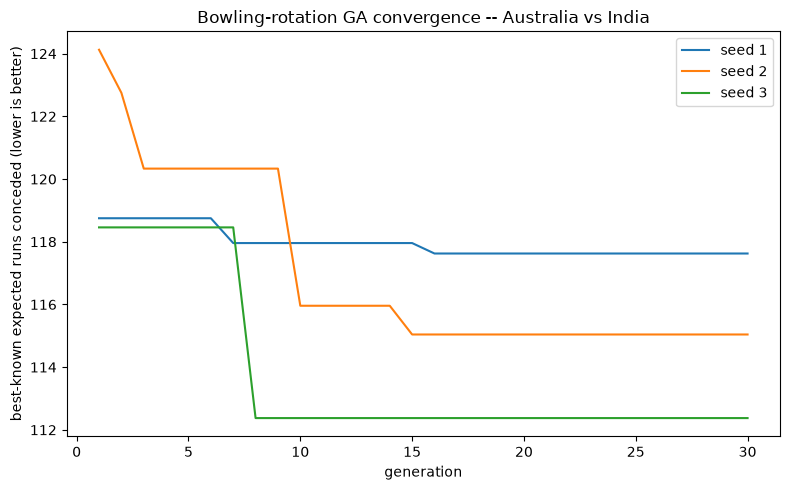

Final expected-runs-conceded across seeds: mean=123.39, std=3.77 (lower std = more run-to-run stability)


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for run in bowling_runs:
    history = run["result"]["fitness_history"]
    ax.plot(range(1, len(history) + 1), [-f for f in history], label=f"seed {run['seed']}")
ax.set_xlabel("generation"); ax.set_ylabel("best-known expected runs conceded (lower is better)")
ax.set_title(f"Bowling-rotation GA convergence -- {TEAM2} vs {TEAM1}")
ax.legend()
plt.tight_layout()
plt.show()

final_runs_conceded = [r["result"]["expected_runs_conceded"] for r in bowling_runs]
print(f"Final expected-runs-conceded across seeds: mean={np.mean(final_runs_conceded):.2f}, "
      f"std={np.std(final_runs_conceded):.2f} (lower std = more run-to-run stability)")

In [10]:
print(f"Running {TEAM1}'s batting-order GA vs {TEAM2}'s bowling, {len(SEEDS)} seeds "
      f"(pop_size={GA_POP}, generations={GA_GEN}).")
batting_runs = []
for seed in SEEDS:
    result = optimize_batting_order(batting_groups_1, bowler_pool_2, outcome_model, batter_profiles,
                                     bowler_profiles, pop_size=GA_POP, generations=GA_GEN,
                                     n_reps=GA_REPS, rng_seed=seed)
    explanation = explain_batting_order(result["batting_order"], result["batting_groups"], bowler_pool_2,
                                         outcome_model, batter_profiles, bowler_profiles, None,
                                         result["expected_score"], "expected_score", rng_seed=seed)
    batting_runs.append({"seed": seed, "result": result, "explanation": explanation})
    print(f"  seed {seed}: final expected score = {result['expected_score']}, "
          f"baseline (SR-sorted) = {explanation['baseline_metric']}, "
          f"improvement = {explanation['improvement_over_baseline']}")

Running India's batting-order GA vs Australia's bowling, 3 seeds (pop_size=24, generations=30).


  seed 1: final expected score = 122.458, baseline (SR-sorted) = 121.4167, improvement = 1.0413


  seed 2: final expected score = 121.708, baseline (SR-sorted) = 125.0417, improvement = -3.3337


  seed 3: final expected score = 121.0, baseline (SR-sorted) = 122.3333, improvement = -1.3333


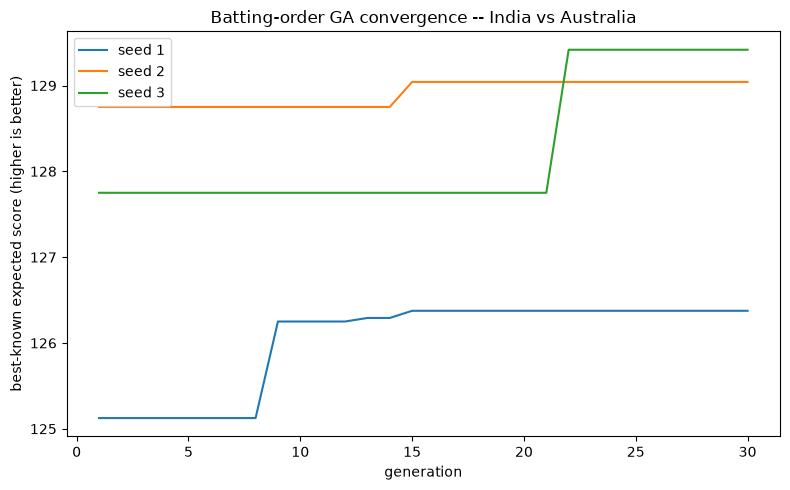

Final expected-score across seeds: mean=121.72, std=0.60 (lower std = more run-to-run stability)


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for run in batting_runs:
    history = run["result"]["fitness_history"]
    ax.plot(range(1, len(history) + 1), history, label=f"seed {run['seed']}")
ax.set_xlabel("generation"); ax.set_ylabel("best-known expected score (higher is better)")
ax.set_title(f"Batting-order GA convergence -- {TEAM1} vs {TEAM2}")
ax.legend()
plt.tight_layout()
plt.show()

final_scores = [r["result"]["expected_score"] for r in batting_runs]
print(f"Final expected-score across seeds: mean={np.mean(final_scores):.2f}, "
      f"std={np.std(final_scores):.2f} (lower std = more run-to-run stability)")

In [12]:
ga_summary = pd.DataFrame([
    {"GA": "Bowling rotation", "metric": "expected runs conceded (lower better)",
     "mean_final": np.mean(final_runs_conceded), "std_across_seeds": np.std(final_runs_conceded),
     "baseline": bowling_runs[0]["explanation"]["baseline_runs_conceded"],
     "mean_improvement_over_baseline": np.mean([r["explanation"]["improvement_over_baseline"] for r in bowling_runs])},
    {"GA": "Batting order", "metric": "expected score (higher better)",
     "mean_final": np.mean(final_scores), "std_across_seeds": np.std(final_scores),
     "baseline": batting_runs[0]["explanation"]["baseline_metric"],
     "mean_improvement_over_baseline": np.mean([r["explanation"]["improvement_over_baseline"] for r in batting_runs])},
]).set_index("GA")
ga_summary

,metric,mean_final,std_across_seeds,baseline,mean_improvement_over_baseline
GA,,,,,
Bowling rotation,expected runs conceded (lower better),123.3900,3.7700,123.4600,0.5700
Batting order,expected score (higher better),121.7220,0.5953,121.4167,-1.2086


**Honest reading of these specific numbers:** at `pop_size=24, generations=30, n_reps=8` (reduced from the CLI's own production defaults of 40/60, chosen here purely for notebook runtime), the improvement over baseline for a single matchup is small and in a couple of seeds even slightly negative -- this is expected, not a bug. `ALGORITHMS.md` §2's own noise-protection design exists precisely because fitness here is a noisy Monte Carlo mean (`n_reps=8` simulated innings): elitism and a 3x-reps re-verification step protect the *tracked best* from ever regressing across a single run's own generations, but they do not guarantee one specific matchup, at these reduced settings, beats one specific naive baseline by a wide margin -- especially since the baselines here (SR-sorted order, even-split rotation) are themselves already fairly reasonable starting points for a well-balanced real XI like India vs Australia, leaving less headroom to improve on. The `std_across_seeds` values above are the more informative stability signal: batting order is markedly more stable (std 0.60) than bowling rotation (std 3.77) at this settings level, consistent with batting order's smaller, role-banded search space converging more reliably than bowling rotation's larger space of legal 20-over sequences.

## Summary

| Part | Headline metric | Result |
|---|---|---|
| A — WPA regressors | Correlation / top-quartile hit-rate (the metrics that matter for a ranking task; `R2` is honestly low for both, expected given per-match variance) | see the metrics table in Part A |
| B — MILP constraint compliance | Every legal-pool constraint satisfied | see the compliance percentages in Part B (should read 100% throughout) |
| B — MILP real-world overlap | AI-recommended XI vs. real historical XI, vs. random-11 baseline | see the bar chart in Part B (full-scale result: `VALIDATION_REPORT.md` §11a/§14) |
| C — GA convergence & stability | Final fitness vs. naive baseline, std across seeds | see the summary table in Part C |

This notebook complements, and cross-references, `model-training/VALIDATION_REPORT.md`
(the full-scale, dated, presentation-facing report) and `ALGORITHMS.md` (why
each algorithm/model was chosen). Re-run this notebook after any change to
the WPA feature set, the MILP constraints, or the GA fitness functions to
confirm nothing regressed.

`conn.close()` below releases the SQLite handle.

In [13]:
conn.close()